# CRISP-DM — Telecom churn prioritization

CMPE-255 • Data mining process assignment • November 3, 2026

Run all cells in order. This notebook is self-contained and Colab-compatible. It uses the bundled CSV when present; otherwise it downloads the exact public Kaggle dataset and checks its SHA-256. Figures, fitted pipelines, and evaluation tables are written to `artifacts/`. Results stored in this notebook were executed locally; a hosted Colab run remains a separate verification. AI assistance: Codex; see the review record and student verification checklist.

## Setup
A CPU runtime is sufficient. In a fresh Colab runtime, run the optional installation cell, then restart the runtime if an installed library was already imported. Pinned dependencies match the verified local run. No API key is required.

In [1]:
# Optional fresh-runtime installation (uncomment if needed):
# %pip install numpy==2.0.2 pandas==2.3.3 scikit-learn==1.6.1 matplotlib==3.9.4 joblib==1.5.3 requests==2.32.5 tabulate==0.9.0

In [2]:
from pathlib import Path
import io, json, hashlib, zipfile, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, requests
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import *
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9,5), 'axes.spines.top':False, 'axes.spines.right':False})
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
def save_json(name, value):
    (ART/name).write_text(json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x,'item') else str(x)))
def figure(name):
    plt.tight_layout(); plt.savefig(ART/name, dpi=150, bbox_inches='tight'); plt.show(); plt.close()
def load_kaggle(slug, filename, expected):
    path = Path('data')/filename
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        response=requests.get('https://www.kaggle.com/api/v1/datasets/download/'+slug, timeout=120)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as z:
            matches=[n for n in z.namelist() if Path(n).name == filename]
            if len(matches)!=1: raise ValueError('Expected exactly one matching CSV in archive')
            path.write_bytes(z.read(matches[0]))
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == expected, 'Dataset version changed; inspect before continuing'
    print('Verified SHA-256:',actual)
    return pd.read_csv(path)
def quality_report(df):
    out=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()})
    out.to_csv(ART/'data_quality.csv'); display(out)
    print('Rows:',len(df),'Exact duplicates:',int(df.duplicated().sum()))
def bootstrap_ci(y, pred, metric, n=500):
    rng=np.random.default_rng(SEED); y=np.asarray(y); pred=np.asarray(pred); vals=[]
    for _ in range(n):
        ix=rng.integers(0,len(y),len(y))
        try: vals.append(metric(y[ix],pred[ix]))
        except ValueError: pass
    return np.quantile(vals,[.025,.975]).tolist()
save_json('environment.json',{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit_learn':sklearn.__version__,'seed':SEED})


Matplotlib is building the font cache; this may take a moment.


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 1. Business understanding
### Objectives, situation, mining goals, and project plan
A hypothetical retention team can review at most 20% of a customer batch. The objective is to concentrate observed churn cases in that review queue. The operational proxy is **lift at 20% ≥ 2**, with average precision above prevalence; a pilot still requires current data and experimental validation. These targets are design assumptions, not a real company commitment.

The sponsor would be a retention manager, the data steward a billing analyst, and the operator a customer-care lead. The available resource is a historical Kaggle teaching dataset and a CPU runtime; there is no campaign response, intervention cost, profit, or timestamped outcome window. Consequently this project estimates cross-sectional churn association, not a verified next-month forecast or causal retention benefit. Cost savings cannot be claimed.

Plan: audit data → lock stratified 60/20/20 split → training-only EDA and CV → validation selection → one final test → batch scoring demonstration → monitored pilot plan. Main risks are timing leakage, changed customer behavior, group disparities, and poor calibration. Success requires reproducibility and honest reporting even when a gate fails.

## 2. Data understanding
### Collection and description
Source: [Kaggle Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). A row represents a customer. `Churn` is the Yes/No outcome; services, billing, contract and tenure describe that customer. ID is a join key, not a predictor. Gender and senior status are retained only for diagnostics. Dataset provenance is included beside the raw CSV.

### Quality verification and initial exploration
Convert blank `TotalCharges` to missing numeric values before measuring quality. Check IDs, labels and nonnegative monetary/tenure fields. A row with missing total charges may be a newly enrolled customer, so median imputation is preferable to silently deleting the row. The full-data audit is restricted to structural quality; relationship exploration uses training rows.

Verified SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


,dtype,missing,unique
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Rows: 7043 Exact duplicates: 0


,n,prevalence
partition,,
test,1409,0.265436
train,4225,0.265325
validation,1409,0.265436


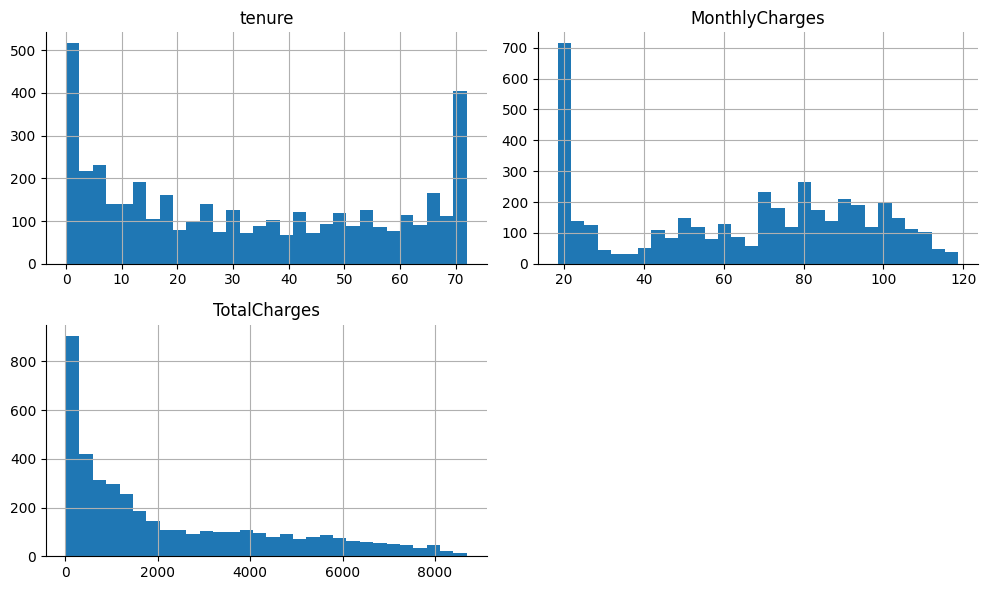

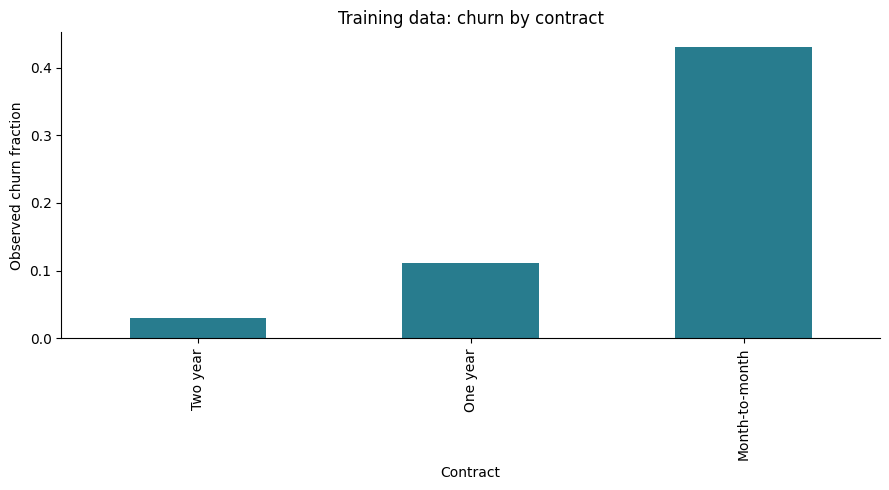

Training charge/tenure correlations:


,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.253173,0.827533
MonthlyCharges,0.253173,1.000000,0.653136
TotalCharges,0.827533,0.653136,1.000000


In [3]:
raw=load_kaggle('blastchar/telco-customer-churn','WA_Fn-UseC_-Telco-Customer-Churn.csv','88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a')
df=raw.copy(); df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
assert df.customerID.is_unique and set(df.Churn)=={'Yes','No'}
assert (df[['tenure','MonthlyCharges','TotalCharges']].dropna()>=0).all().all()
quality_report(df)
y=df.Churn.eq('Yes').astype(int)
train_idx,other_idx=train_test_split(df.index,test_size=.4,stratify=y,random_state=SEED)
val_idx,test_idx=train_test_split(other_idx,test_size=.5,stratify=y.loc[other_idx],random_state=SEED)
assert not(set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))
splits=pd.Series('train',index=df.index);splits.loc[val_idx]='validation';splits.loc[test_idx]='test'
pd.DataFrame({'row_id':df.index,'partition':splits}).to_csv(ART/'split_manifest.csv',index=False)
display(pd.DataFrame({'partition':splits,'churn':y}).groupby('partition').agg(n=('churn','size'),prevalence=('churn','mean')))
train=df.loc[train_idx].copy()
train[['tenure','MonthlyCharges','TotalCharges']].hist(bins=30,figsize=(10,6));figure('training_distributions.png')
train.assign(churn=y.loc[train_idx]).groupby('Contract').churn.mean().sort_values().plot.bar(color='#287c8e',ylabel='Observed churn fraction',title='Training data: churn by contract');figure('training_contract_churn.png')
print('Training charge/tenure correlations:'); display(train[['tenure','MonthlyCharges','TotalCharges']].corr())


## 3. Data preparation
### Selection, cleaning, construction, integration and formatting
Exclude `customerID`, `Churn`, `gender`, and `SeniorCitizen` from predictors. This reduces direct demographic use but does not guarantee fairness: other variables can be proxies. One source is used; no external join is needed. Integrate labels by preserved row index, not position after sorting.

Numeric features are median-imputed and standardized. Other columns are imputed with their training mode and one-hot encoded, allowing unseen categories at prediction time. Existing service categories are meaningful, including “No internet service”; they are preserved. No target-driven feature filtering or outlier removal is applied. Learned preprocessing is inside the pipeline and refit within every CV fold. One-hot columns are the constructed features; additional tenure/charge ratios are avoided because they are redundant and introduce undefined division at zero tenure.

In [4]:
features=[c for c in df if c not in ['customerID','Churn','gender','SeniorCitizen']]
X=df[features]; numeric=['tenure','MonthlyCharges','TotalCharges']; categorical=[c for c in features if c not in numeric]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),categorical)])
Xtr,Xv,Xte=X.loc[train_idx],X.loc[val_idx],X.loc[test_idx]
ytr,yv,yte=y.loc[train_idx],y.loc[val_idx],y.loc[test_idx]
save_json('schema.json',{'features':features,'numeric':numeric,'categorical':categorical,'excluded':['customerID','Churn','gender','SeniorCitizen'],'categories':{c:sorted(Xtr[c].dropna().unique().tolist()) for c in categorical},'numeric_ranges':{c:[float(Xtr[c].min()),float(Xtr[c].max())] for c in numeric}})


## 4. Modeling
### Technique selection, test design, model building and assessment
The baseline returns training prevalence. Logistic regression supplies an interpretable additive benchmark; a forest can capture nonlinear interactions. Use three-fold stratified CV on training rows, tuning C for logistic regression and leaf size for the forest. Average precision (AP) is the training selection metric because positive outcomes are less common. Validation AP selects between the tuned families; ties favor the simpler logistic model. No test result is used for this choice. Keep the training fit unchanged after selection so validation and test comparisons have the same training budget.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
configs={'logistic':(LogisticRegression(max_iter=2000,random_state=SEED),{'model__C':[.1,1.,10.]}),'random_forest':(RandomForestClassifier(n_estimators=150,max_features='sqrt',random_state=SEED,n_jobs=1),{'model__min_samples_leaf':[3,10]})}
models={}; rows=[]
for name,(est,grid) in configs.items():
    search=GridSearchCV(Pipeline([('pre',clone(pre)),('model',est)]),grid,scoring='average_precision',cv=cv,n_jobs=1)
    search.fit(Xtr,ytr); models[name]=search.best_estimator_
    pd.DataFrame(search.cv_results_).to_csv(ART/(name+'_cv.csv'),index=False)
    rows.append({'model':name,'cv_AP':search.best_score_,'validation_AP':average_precision_score(yv,search.predict_proba(Xv)[:,1]),'parameters':str(search.best_params_)})
comparison=pd.DataFrame(rows).sort_values('validation_AP',ascending=False,kind='stable');display(comparison);comparison.to_csv(ART/'model_comparison.csv',index=False)
winner=comparison.iloc[0]['model']; model=models[winner]
baseline=DummyClassifier(strategy='prior').fit(Xtr,ytr)
print('Frozen winner:',winner)


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python

,model,cv_AP,validation_AP,parameters
0,logistic,0.663555,0.677076,{'model__C': 1.0}
1,random_forest,0.664477,0.674679,{'model__min_samples_leaf': 10}


Frozen winner: logistic


## 5. Evaluation
### Results, process review, and next steps
The contact policy selects the highest-scoring floor(0.20×N) customers in each batch, with stable input-order tie breaking. This is a rank policy, not a probability cutoff optimized on test data. The confusion matrix uses a separate, fixed 0.5 threshold for diagnostic reporting.

Evaluate discrimination, probability quality, and ranking value; estimate a 95% percentile bootstrap interval with 500 resamples. This interval conditions on the trained model and this sample design, so it excludes retraining and future-distribution uncertainty. Group metrics are diagnostic and may be noisy; excluding demographics is not a fairness certification. Business readiness requires both the proxy gate and current, correctly timed data. A randomized contact pilot is needed to establish intervention benefit.

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

,AP,ROC_AUC,Brier,accuracy_0.5,precision_at_20pct,recall_at_20pct,lift_at_20pct,contacts
validation,0.677076,0.859725,0.130481,0.823989,0.711744,0.534759,2.681409,281.0
test,0.622180,0.832326,0.141547,0.784954,0.615658,0.462567,2.319419,281.0
test_baseline,0.265436,0.500000,0.194980,0.734564,0.274021,0.205882,1.032342,281.0


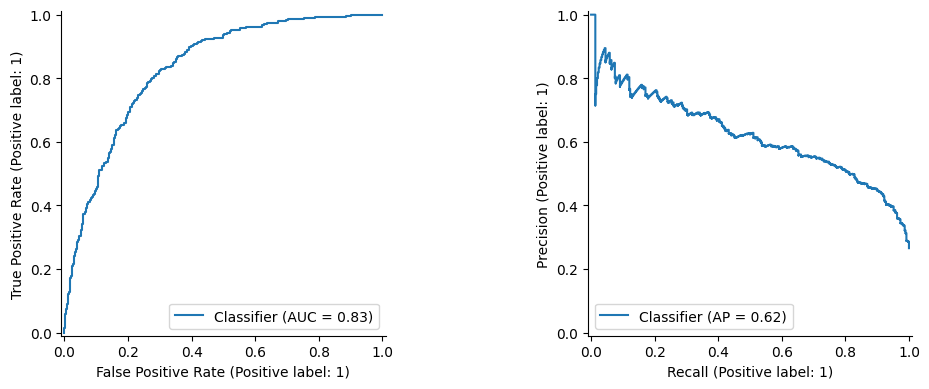

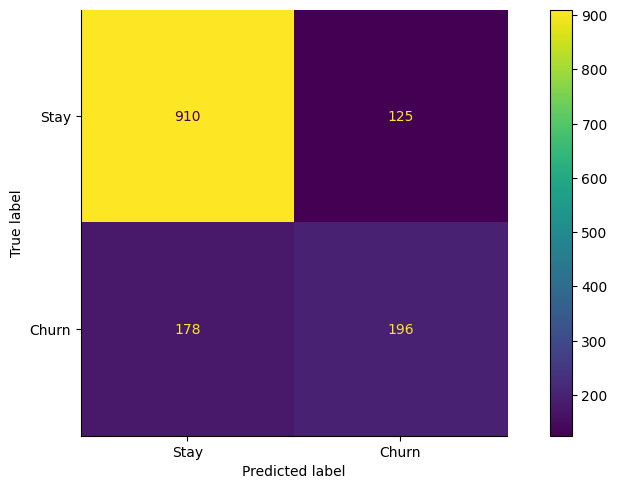

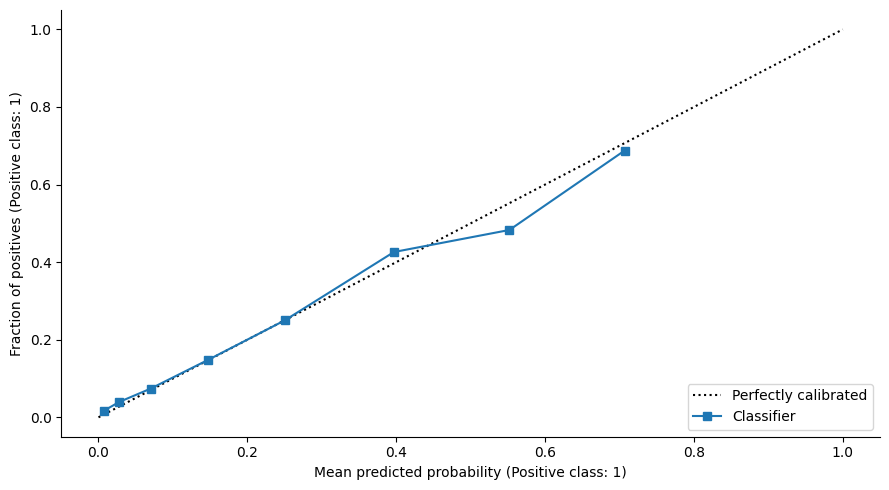

,attribute,group,n,prevalence,AP,TPR_0.5,FPR_0.5
0,gender,Female,714,0.289916,0.611509,0.526570,0.151874
1,gender,Male,695,0.240288,0.638886,0.520958,0.090909
2,SeniorCitizen,0,1170,0.232479,0.607149,0.507353,0.099109
3,SeniorCitizen,1,239,0.426778,0.665438,0.568627,0.262774


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

,feature,AP_drop,sd
2,tenure,0.277290,0.005624
5,InternetService,0.075548,0.011866
16,TotalCharges,0.054508,0.013166
12,Contract,0.052274,0.014653
15,MonthlyCharges,0.037067,0.007087
13,PaperlessBilling,0.015760,0.003944
14,PaymentMethod,0.012698,0.008760
9,TechSupport,0.011476,0.008234
6,OnlineSecurity,0.009027,0.009271
4,MultipleLines,0.008111,0.004871


In [6]:
def ranked_metrics(y,p):
    yy=np.asarray(y); n=max(1,int(.2*len(yy))); ix=np.argsort(-np.asarray(p),kind='stable')[:n]
    precision=yy[ix].mean(); return {'precision_at_20pct':float(precision),'recall_at_20pct':float(yy[ix].sum()/yy.sum()),'lift_at_20pct':float(precision/yy.mean()),'contacts':n}
def clf_metrics(y,p):
    return {'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),'Brier':brier_score_loss(y,p),'accuracy_0.5':accuracy_score(y,np.asarray(p)>=.5),**ranked_metrics(y,p)}
pv=model.predict_proba(Xv)[:,1]; pt=model.predict_proba(Xte)[:,1]; pb=baseline.predict_proba(Xte)[:,1]
metrics={'winner':winner,'validation':clf_metrics(yv,pv),'test':clf_metrics(yte,pt),'test_baseline':clf_metrics(yte,pb),'test_AP_CI95':bootstrap_ci(yte,pt,average_precision_score),'test_lift_CI95':bootstrap_ci(yte,pt,lambda a,b:ranked_metrics(a,b)['lift_at_20pct'])}
metrics['proxy_gate_passed']=bool(metrics['test']['lift_at_20pct']>=2 and metrics['test']['AP']>yte.mean())
save_json('metrics.json',metrics);display(pd.DataFrame({k:v for k,v in metrics.items() if isinstance(v,dict)}).T)
pd.DataFrame({'row_id':test_idx,'observed':yte.to_numpy(),'probability':pt}).to_csv(ART/'test_predictions.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4));RocCurveDisplay.from_predictions(yte,pt,ax=axs[0]);PrecisionRecallDisplay.from_predictions(yte,pt,ax=axs[1]);figure('test_discrimination.png')
ConfusionMatrixDisplay.from_predictions(yte,pt>=.5,display_labels=['Stay','Churn']);figure('test_confusion.png')
from sklearn.calibration import CalibrationDisplay
CalibrationDisplay.from_predictions(yte,pt,n_bins=8,strategy='quantile');figure('test_calibration.png')
group_rows=[]
for col in ['gender','SeniorCitizen']:
    for value,idx in df.loc[test_idx].groupby(col).groups.items():
        mask=pd.Index(test_idx).isin(idx); yy=yte.to_numpy()[mask]; pp=pt[mask]; pred=pp>=.5
        group_rows.append({'attribute':col,'group':str(value),'n':len(yy),'prevalence':yy.mean(),'AP':average_precision_score(yy,pp),'TPR_0.5':recall_score(yy,pred,zero_division=0),'FPR_0.5':float(pred[yy==0].mean())})
groups=pd.DataFrame(group_rows);display(groups);groups.to_csv(ART/'subgroup_metrics.csv',index=False)
from sklearn.inspection import permutation_importance
imp=permutation_importance(model,Xv,yv,scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':features,'AP_drop':imp.importances_mean,'sd':imp.importances_std}).sort_values('AP_drop',ascending=False)
importance.to_csv(ART/'validation_importance.csv',index=False);display(importance.head(10))


## 6. Deployment
### Deployment plan and executed handoff
Export the complete preprocessing/model pipeline, schema, frozen policy, sample input, and sample predictions. The local batch demo is the deployment artifact; no public service or real customer campaign is claimed. Load only trusted joblib files. A production integration would score a newly validated, pre-outcome snapshot, rank by probability, and let customer-care staff review the top 20%.

### Monitoring and maintenance
Suggested owner: customer-care analytics. On every batch, reject missing required columns or invalid negative numerical values; report unknown category rate and numeric drift. Review weekly: missingness >5%, unknown categories >1%, and population stability index >0.2 trigger investigation. When outcomes mature, compare AP/lift and calibration with this benchmark; a lift below 2 for two batches pauses the pilot. These are proposed thresholds, not empirically calibrated alerts. Retraining requires a new time-separated holdout and approval from the operational owner. Roll back to no model-driven prioritization if quality checks fail.

### Final report and project review
See `report.md`, `article_medium.md`, and `walkthrough.md`. Limitations include historical teaching data, unknown timing, associations rather than causal effects, and untested production generalization. The technical outcome is a reproducible ranking prototype and an explicit decision gate, not demonstrated retention savings.

In [7]:
joblib.dump(model,ART/'model.joblib'); restored=joblib.load(ART/'model.joblib')
np.testing.assert_allclose(restored.predict_proba(Xte.iloc[:20]),model.predict_proba(Xte.iloc[:20]))
sample=Xte.iloc[:5].copy(); sample.to_csv(ART/'sample_input.csv',index=False)
pd.DataFrame({'churn_probability':restored.predict_proba(sample)[:,1]}).to_csv(ART/'sample_output.csv',index=False)
unseen=sample.copy(); unseen.loc[unseen.index[0],'Contract']='Previously unseen plan'
assert np.isfinite(restored.predict_proba(unseen)).all()
missing=sample.copy(); missing.loc[missing.index[0],'TotalCharges']=np.nan
assert np.isfinite(restored.predict_proba(missing)).all()
save_json('policy.json',{'type':'batch_top_fraction','fraction':.2,'tie_break':'stable_input_order','classification_diagnostic_threshold':.5})
save_json('verification.json',{'disjoint_splits':True,'pipeline_roundtrip':True,'unseen_category':True,'missing_charge':True,'finite_probabilities':bool(np.isfinite(pt).all()),'human_review_completed':False})
print('Saved deployable pipeline and batch example. Proxy gate:',metrics['proxy_gate_passed'])


Saved deployable pipeline and batch example. Proxy gate: True
